# Model 3 — Vision Transformer (ViT-B/16)
A pure-attention model: the image is cut into 16x16 patches and processed by 12 transformer layers with global self-attention, pretrained on ImageNet and fine-tuned here.

Same dataset split, class order, class weights, focal loss (α=0.25, γ=2), Adam-style optimiser with ReduceLROnPlateau + early stopping on val loss, and the same test metrics as the Attention U-Net, so the comparison is like-for-like.

In [1]:
import os, sys, json, time
import numpy as np, matplotlib.pyplot as plt, seaborn as sns, torch, torch.nn as nn
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
sys.path.insert(0, os.getcwd())          # common.py sits next to this notebook
from common import *

DATASET_PATH = r"C:\Users\pooja\Desktop\dp\Diabetic Retenopathy.v8i.folder.new_updated"
OUT_DIR      = r"C:\Users\pooja\Desktop\dp\model_comparison"
RUN_DIR      = os.path.join(OUT_DIR, "vit_b16"); os.makedirs(RUN_DIR, exist_ok=True)
CFG = {
    "batch_size": 32,
    "focal_alpha": 0.25,
    "focal_gamma": 2.0,
    "reduce_lr_patience": 3,
    "early_stopping_patience": 5,
    "epochs": 15,
    "lr": 3e-05,
    "weight_decay": 0.05
}

seed_all(42)
torch.backends.cudnn.benchmark = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")

torch 2.11.0+cu128 | NVIDIA GeForce RTX 5070 Ti Laptop GPU


<!-- theory -->
## Data preparation
* Images are resized to **224×224** and normalised to the range the pretrained models expect.
* **Data augmentation** (random rotation, flips, shift, zoom, brightness) creates new views of each eye image so the model doesn't memorise the training set.
* All images are loaded into RAM once and augmented on the GPU for speed.


In [2]:
print("Loading images (uint8, kept in RAM)...")
t = time.time()
data = {s: load_split(DATASET_PATH, s) for s in ["train", "validation", "test"]}
print(f"done in {time.time()-t:.0f}s")

Loading images (uint8, kept in RAM)...
  train     :  12716 images  [1206, 3304, 6499, 1020, 687]
  validation:   1696 images  [161, 441, 867, 136, 91]
  test      :   2544 images  [241, 661, 1300, 204, 138]
done in 17s


<!-- theory -->
## Vision Transformer (ViT-B/16)
* The image is cut into **196 small patches** (16×16 pixels), treated like words in a sentence.
* Each patch becomes a vector; a special **[CLS] token** is added to summarise the whole image, plus position info.
* **12 transformer layers** with **self-attention**: every patch looks at every other patch, so the model sees the **whole retina at once**.
* This suits DR grading, because severity depends on how many lesions there are and how spread out they are.
* The [CLS] output goes to a new 5-grade classifier. 85.8M parameters.


In [3]:
from torchvision.models import vit_b_16, ViT_B_16_Weights

def build_model():
    """ViT-B/16 (86M params), ImageNet-1k pretrained, new 5-way head, fine-tuned end to end."""
    m = vit_b_16(weights=ViT_B_16_Weights.IMAGENET1K_V1)
    m.heads.head = nn.Linear(m.heads.head.in_features, 5)
    return m
model = build_model().to(device).to(memory_format=torch.channels_last)
n_params = sum(p.numel() for p in model.parameters())
print(model.__class__.__name__, f"{n_params:,} parameters")

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to C:\Users\pooja/.cache\torch\hub\checkpoints\vit_b_16-c867db91.pth


100.0%


VisionTransformer 85,802,501 parameters


<!-- theory -->
## Transfer learning
* The ViT was **pretrained on ImageNet** (1.2M everyday photos), so it already knows edges, textures and shapes.
* It is **fine-tuned** on the eye images with a very small learning rate, so the pretrained knowledge is adjusted, not destroyed.
* Only the final 5-grade layer is new.


## Class imbalance
More than half the images are healthy (No_DR), so the model could cheat by always predicting it.
* **Class weights** — rare grades (e.g. Severe) count more in the loss.
* **Focal loss** — reduces the loss for easy, confident images so training focuses on hard and rare cases.


## Training
* **Optimiser (Adam/AdamW)** updates the weights to reduce the loss.
* **Learning-rate reduction** lowers the step size when validation loss stops improving.
* **Early stopping** stops training when it stops improving and keeps the best weights.
* **Mixed precision (FP16)** makes training on the GPU about 2× faster.


In [4]:
history, train_time_s, cw = train(model, data, CFG, device, os.path.join(RUN_DIR, "best_model.pt"))
print(f"Training time: {train_time_s/60:.1f} min | class weights: {np.round(cw, 3)}")

Epoch  1/15  loss 0.1372  acc 0.6936 | val_loss 0.1032  val_acc 0.7447  val_bal_acc 0.6624  lr 3.0e-05  [65s]  * saved
Epoch  2/15  loss 0.1060  acc 0.7627 | val_loss 0.0987  val_acc 0.7665  val_bal_acc 0.6752  lr 3.0e-05  [130s]  * saved
Epoch  3/15  loss 0.0929  acc 0.7763 | val_loss 0.1123  val_acc 0.7577  val_bal_acc 0.6680  lr 3.0e-05  [195s]
Epoch  4/15  loss 0.0841  acc 0.8022 | val_loss 0.0994  val_acc 0.7748  val_bal_acc 0.6567  lr 3.0e-05  [262s]
Epoch  5/15  loss 0.0763  acc 0.8108 | val_loss 0.0872  val_acc 0.8237  val_bal_acc 0.7135  lr 3.0e-05  [329s]  * saved
Epoch  6/15  loss 0.0665  acc 0.8250 | val_loss 0.0709  val_acc 0.8160  val_bal_acc 0.7622  lr 3.0e-05  [397s]  * saved
Epoch  7/15  loss 0.0615  acc 0.8407 | val_loss 0.0809  val_acc 0.7983  val_bal_acc 0.7227  lr 3.0e-05  [465s]
Epoch  8/15  loss 0.0512  acc 0.8547 | val_loss 0.0814  val_acc 0.8355  val_bal_acc 0.7676  lr 3.0e-05  [533s]
Epoch  9/15  loss 0.0468  acc 0.8708 | val_loss 0.0853  val_acc 0.8585  val_b

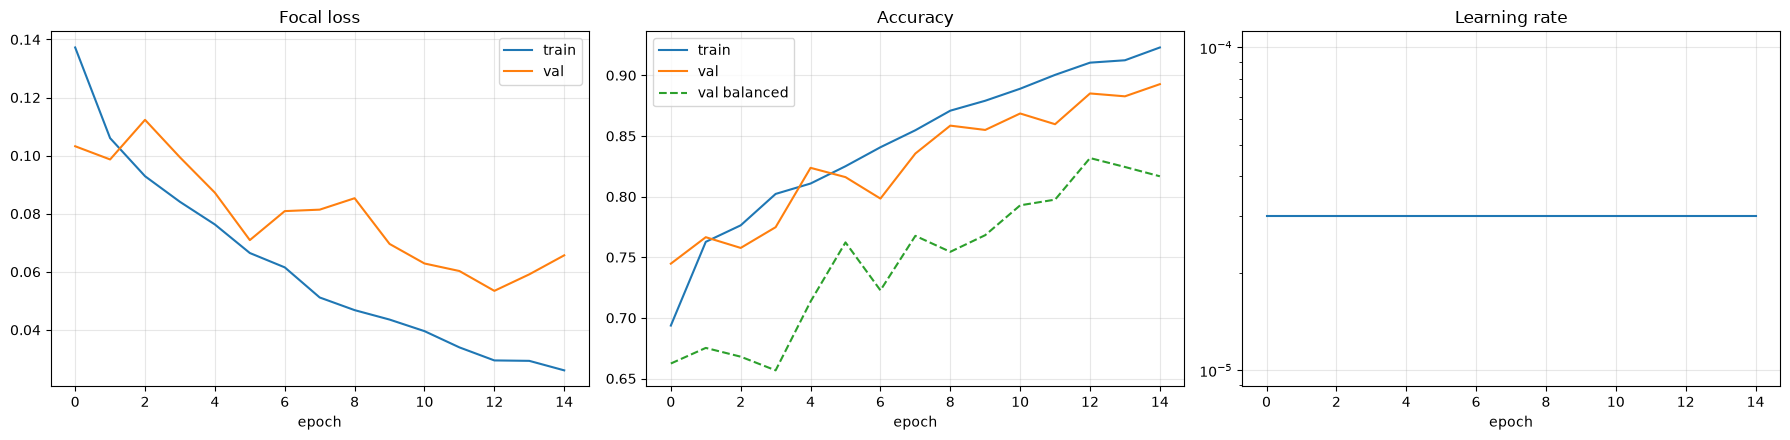

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].plot(history["loss"], label="train"); ax[0].plot(history["val_loss"], label="val"); ax[0].set_title("Focal loss")
ax[1].plot(history["accuracy"], label="train"); ax[1].plot(history["val_accuracy"], label="val"); ax[1].set_title("Accuracy")
ax[1].plot(history["val_balanced_accuracy"], label="val balanced", ls="--")
ax[2].plot(history["lr"]); ax[2].set_yscale("log"); ax[2].set_title("Learning rate")
for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3)
ax[0].legend(); ax[1].legend(); plt.tight_layout()
plt.savefig(os.path.join(RUN_DIR, "training_history.png"), dpi=200); plt.show()

<!-- theory -->
## How the model is evaluated
* **Accuracy** — % of test images graded correctly (can look good just by predicting "No_DR").
* **Balanced accuracy** — average accuracy over the 5 grades, so rare grades count equally. Main metric.
* **Precision / Recall / F1** — per grade: how often a prediction is right / how many images of that grade are found / a balance of both.
* **Cohen's kappa** — agreement with the true labels beyond chance (1 = perfect).
* **Confusion matrix** — shows which grades get mixed up.
* **ROC-AUC** — how well the model separates one grade from the rest (1 = perfect).


                precision    recall  f1-score   support

          Mild     0.6716    0.7469    0.7073       241
      Moderate     0.8642    0.7700    0.8144       661
         No_DR     0.9883    0.9777    0.9830      1300
Proliferate_DR     0.6744    0.8529    0.7532       204
        Severe     0.7063    0.7319    0.7189       138

      accuracy                         0.8785      2544
     macro avg     0.7810    0.8159    0.7954      2544
  weighted avg     0.8856    0.8785    0.8803      2544

{'accuracy': 0.8785, 'balanced_accuracy': 0.8159, 'kappa': 0.8161, 'quadratic_kappa': 0.7549, 'macro_f1': 0.7954, 'macro_auc': 0.9738}
saved -> C:\Users\pooja\Desktop\dp\model_comparison\results\vit_b16.json


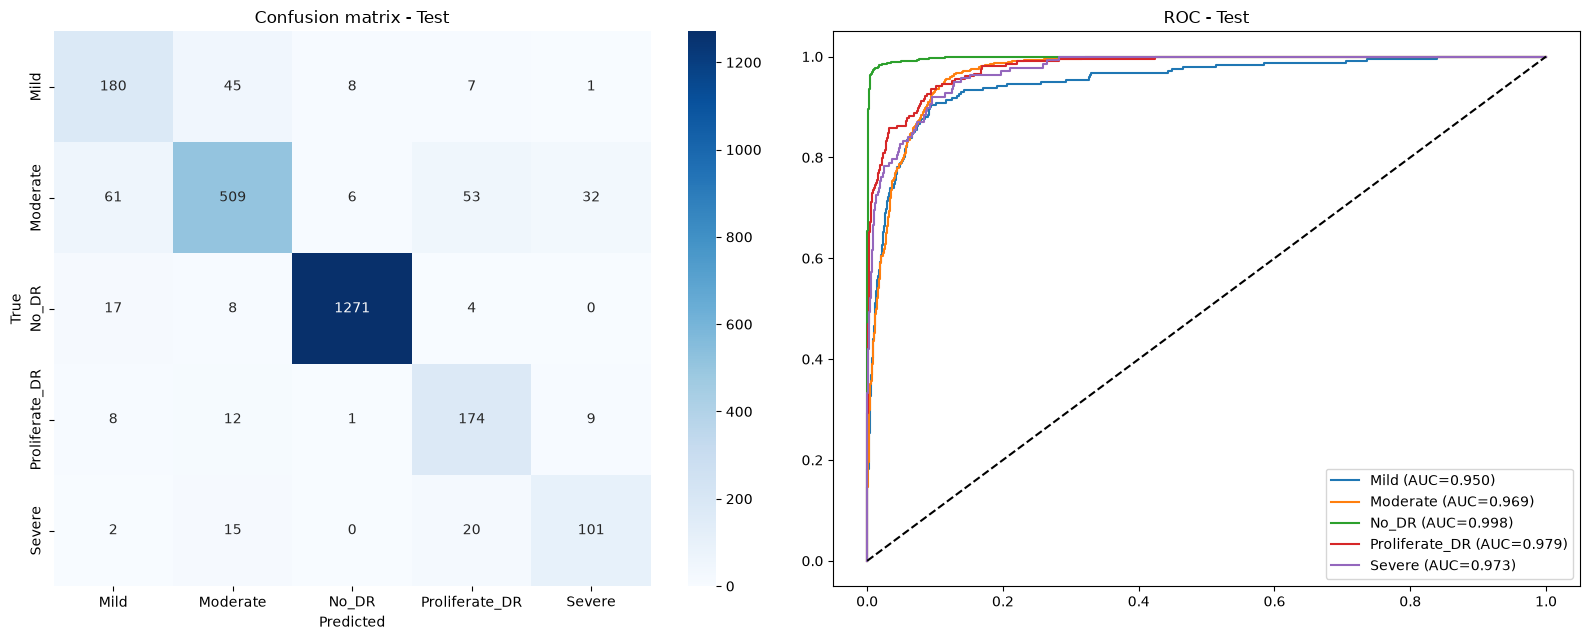

In [6]:
xte, yte = data["test"]
prob = predict(model, xte, device)
y = yte.numpy()
res = save_results(os.path.join(OUT_DIR, "results", "vit_b16.json"), "ViT-B/16", y, prob, {
    "params": n_params, "epochs_trained": len(history["loss"]), "train_time_s": train_time_s,
    "inference_ms_per_img": inference_ms(model, device), "framework": f"PyTorch {torch.__version__}",
    "history": history})

fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
cm = confusion_matrix(y, prob.argmax(1))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[0])
ax[0].set_title("Confusion matrix - Test"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True")
for i, c in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y == i, prob[:, i]); ax[1].plot(fpr, tpr, label=f"{c} (AUC={roc_auc_score(y == i, prob[:, i]):.3f})")
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].legend(loc="lower right"); ax[1].set_title("ROC - Test")
plt.tight_layout(); plt.savefig(os.path.join(RUN_DIR, "test_cm_roc.png"), dpi=200); plt.show()